# 🏥 Healthcare EDA Project
## Patient Readmission Risk Analysis

---

**Name:** AYESHA SIDDIQA

**Date:** 21-09-2026

**Instructor:** ESA SYED

---

## 📖 Project Overview

This notebook is your **end-to-end EDA** on a 500,000-record synthetic healthcare dataset. You'll follow six phases, from data loading to business recommendations.

**Read these first:**
- [PROJECT_GUIDE.md](../PROJECT_GUIDE.md) — Full task descriptions
- [HINTS.md](../HINTS.md) — Optional hints per phase
- [SETUP_GUIDE.md](../SETUP_GUIDE.md) — Environment setup

**Rules:**
- Complete every `# YOUR CODE HERE` section
- Write observations in the markdown cells
- Do not delete the structure — add to it
- Commit often

---
# 📦 Section 1: Setup & Imports

Run the cell below to import all required libraries.

In [4]:
# Core Libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Interactive EDA
import dtale

# Utilities
import warnings
warnings.filterwarnings('ignore')

# Visualization Settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

print('✅ All libraries imported successfully!')

✅ All libraries imported successfully!


---
# 🔍 Section 2: Data Loading & Initial Inspection

**Phase 1** — Understand the dataset structure before doing anything else.

---

## Task 1.1: Load the Dataset

The dataset is loaded from a raw GitHub URL. If this fails, see `SETUP_GUIDE.md` → Option B.

In [5]:

# STUDENT CODE: Load the CSV using pd.read_csv()
df = pd.read_csv("../data/synthetic_healthcare_20250901.csv")

# Display first 5 rows
df.head()

,patient_id,age,gender,admission_type,primary_diagnosis,hospital_department,length_of_stay,systolic_bp,diastolic_bp,heart_rate,temperature,hemoglobin,creatinine,glucose,comorbidity_count,medication_count,insurance_type,admission_date,discharge_date,readmission_risk,total_cost
0,HC0000001,51,M,Trauma,Neurological,Emergency,4,114.0,78.0,87.0,98.8,11.7,1.52,128.0,2,6,Other,2023-01-27,2023-01-31,1,6537.66
1,HC0000002,46,F,Elective,Gastrointestinal,General Medicine,4,127.0,74.0,NaN,96.5,14.3,1.05,117.0,1,3,Self-Pay,2023-12-28,2024-01-01,0,7314.44
2,HC0000003,63,M,Elective,Orthopedic,Pediatrics,2,136.0,73.0,66.0,99.0,14.8,0.41,55.0,0,7,Medicaid,2023-03-05,2023-03-07,0,5195.45
3,HC0000004,62,F,Trauma,Neurological,ICU,5,131.0,88.0,53.0,98.8,13.6,1.61,55.0,2,7,Self-Pay,2023-03-21,2023-03-26,0,15253.74
4,HC0000005,54,F,Urgent,Respiratory,Emergency,9,104.0,57.0,85.0,98.6,13.1,1.23,112.0,1,10,Private,2022-12-23,2023-01-01,0,9764.80


## Task 1.2: Dataset Shape

**YOUR TASK:** Print the number of rows and columns.

In [6]:
df.shape



(500000, 21)

## Task 1.3: Data Types & Info

**YOUR TASK:** Display the data types and memory usage of each column.

In [7]:
df.info()



<class 'pandas.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 21 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   patient_id           500000 non-null  str    
 1   age                  500000 non-null  int64  
 2   gender               500000 non-null  str    
 3   admission_type       500000 non-null  str    
 4   primary_diagnosis    500000 non-null  str    
 5   hospital_department  500000 non-null  str    
 6   length_of_stay       500000 non-null  int64  
 7   systolic_bp          496983 non-null  float64
 8   diastolic_bp         497146 non-null  float64
 9   heart_rate           497020 non-null  float64
 10  temperature          497020 non-null  float64
 11  hemoglobin           498946 non-null  float64
 12  creatinine           498940 non-null  float64
 13  glucose              498949 non-null  float64
 14  comorbidity_count    500000 non-null  int64  
 15  medication_count     500000 

## Task 1.4: Statistical Summary

**YOUR TASK:** Generate summary statistics for numerical columns.

In [8]:
df.describe()


,age,length_of_stay,systolic_bp,diastolic_bp,heart_rate,temperature,hemoglobin,creatinine,glucose,comorbidity_count,medication_count,readmission_risk,total_cost
count,500000.000000,500000.000000,496983.000000,497146.000000,497020.000000,497020.000000,498946.000000,498940.000000,498949.000000,500000.000000,500000.000000,500000.000000,500000.000000
mean,61.450434,5.848698,128.095145,74.419746,78.160194,98.605895,13.502835,1.473405,116.044891,2.172898,7.073230,0.686888,10997.343328
std,17.067469,11.213647,20.027506,15.396561,14.628445,1.112992,1.780488,0.649654,38.077052,1.708277,6.745928,0.801423,4303.154700
min,5.000000,1.000000,75.000000,45.000000,45.000000,95.000000,6.000000,0.300000,55.000000,0.000000,0.000000,0.000000,2713.250000
25%,51.000000,2.000000,115.000000,64.000000,68.000000,97.900000,12.300000,1.010000,90.000000,1.000000,4.000000,0.000000,7911.440000
50%,61.000000,4.000000,128.000000,74.000000,78.000000,98.600000,13.500000,1.350000,115.000000,2.000000,6.000000,0.000000,9987.410000
75%,72.000000,6.000000,141.000000,85.000000,88.000000,99.300000,14.700000,1.790000,140.000000,3.000000,8.000000,1.000000,13106.520000
max,125.000000,119.000000,349.888828,130.000000,279.760584,114.992080,20.000000,9.530000,899.940868,12.000000,69.000000,2.000000,60956.600000


## Task 1.5: Missing Values

**YOUR TASK:** Identify which columns have missing values and how many.

In [9]:
df.isnull().sum()



patient_id                0
age                       0
gender                    0
admission_type            0
primary_diagnosis         0
hospital_department       0
length_of_stay            0
systolic_bp            3017
diastolic_bp           2854
heart_rate             2980
temperature            2980
hemoglobin             1054
creatinine             1060
glucose                1051
comorbidity_count         0
medication_count          0
insurance_type            0
admission_date            0
discharge_date            0
readmission_risk          0
total_cost                0
dtype: int64

## Task 1.6: Categorical Columns — Unique Values

**YOUR TASK:** Loop through categorical columns and print their unique values.

This will help identify data quality issues (e.g., 'Male' vs 'male').

In [10]:
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}:")
    print(df[col].unique())




patient_id:
<StringArray>
['HC0000001', 'HC0000002', 'HC0000003', 'HC0000004', 'HC0000005', 'HC0000006', 'HC0000007', 'HC0000008', 'HC0000009', 'HC0000010',
 ...
 'HC0499991', 'HC0499992', 'HC0499993', 'HC0499994', 'HC0499995', 'HC0499996', 'HC0499997', 'HC0499998', 'HC0499999', 'HC0500000']
Length: 500000, dtype: str

gender:
<StringArray>
['M', 'F']
Length: 2, dtype: str

admission_type:
<StringArray>
['Trauma', 'Elective', 'Urgent', 'Emergency']
Length: 4, dtype: str

primary_diagnosis:
<StringArray>
['Neurological', 'Gastrointestinal', 'Orthopedic', 'Respiratory', 'Cardiovascular']
Length: 5, dtype: str

hospital_department:
<StringArray>
['Emergency', 'General Medicine', 'Pediatrics', 'ICU', 'Cardiology', 'Surgery']
Length: 6, dtype: str

insurance_type:
<StringArray>
['Other', 'Self-Pay', 'Medicaid', 'Private', 'Medicare']
Length: 5, dtype: str

admission_date:
<StringArray>
['2023-01-27', '2023-12-28', '2023-03-05', '2023-03-21', '2022-12-23', '2022-12-04', '2022-05-01', '2023-

## Task 1.7: Launch D-Tale for Interactive Exploration

**YOUR TASK:** Launch D-Tale and explore the dataset in your browser.

In D-Tale, look at:
- **Describe** tab — Summary stats
- **Missing** tab — Missing value patterns
- **Correlations** tab — Quick correlation checks

In [75]:
dtale.show(df)



### 📝 Initial Observations

**YOUR TASK:** Write 3-5 observations about the data.


**Your Observations:**

1. The dataset contains 500,000 records and 21 columns
2. The dataset contains numerical,and date related values
3. Missing values are present in 7 columns: systolic_bp,diastolic_bp,heart_rate,temperature,hemoglobin,creatinine,glucose  
4. The categorial variables contain consistent values with no obvious spelling or caase inconsistencies
5. The numerical summary shows some potentially extreme values, particularly for length_of_stay, heart_rate, glucose, and medication_count, which should be investigated during the data-cleaning phase.

---
# 🧹 Section 3: Data Cleaning & Preprocessing

**Phase 2** — Clean the data before analysis.

> ⚠️ **Before writing any code**, decide your strategy for each issue and write it in the markdown cells.

In [12]:
missing_cols=df.columns[df.isnull().any()]
df[missing_cols].describe()

,systolic_bp,diastolic_bp,heart_rate,temperature,hemoglobin,creatinine,glucose
count,496983.000000,497146.000000,497020.000000,497020.000000,498946.000000,498940.000000,498949.000000
mean,128.095145,74.419746,78.160194,98.605895,13.502835,1.473405,116.044891
std,20.027506,15.396561,14.628445,1.112992,1.780488,0.649654,38.077052
min,75.000000,45.000000,45.000000,95.000000,6.000000,0.300000,55.000000
25%,115.000000,64.000000,68.000000,97.900000,12.300000,1.010000,90.000000
50%,128.000000,74.000000,78.000000,98.600000,13.500000,1.350000,115.000000
75%,141.000000,85.000000,88.000000,99.300000,14.700000,1.790000,140.000000
max,349.888828,130.000000,279.760584,114.992080,20.000000,9.530000,899.940868


## Task 2.1: Handle Missing Values

**Plan (write your strategy first):**

- systolic_bp → Median
- diastolic_bp → Median
- heart_rate → Median
- temperature → Median
- hemoglobin → Median
- creatinine → Median
- glucose → Median



In [13]:
# Save original shape
original_shape = df.shape
print('Original shape:', original_shape)

# YOUR CODE HERE
# Handle missing values based on your strategy above
missing_cols = df.columns[df.isnull().any()]

for col in missing_cols:
    df[col] = df[col].fillna(df[col].median())
    
# Verify: No unexpected missing values remain
print('Missing values after cleaning:')
print(df.isnull().sum())

print('New shape:', df.shape)

Original shape: (500000, 21)
Missing values after cleaning:
patient_id             0
age                    0
gender                 0
admission_type         0
primary_diagnosis      0
hospital_department    0
length_of_stay         0
systolic_bp            0
diastolic_bp           0
heart_rate             0
temperature            0
hemoglobin             0
creatinine             0
glucose                0
comorbidity_count      0
medication_count       0
insurance_type         0
admission_date         0
discharge_date         0
readmission_risk       0
total_cost             0
dtype: int64
New shape: (500000, 21)


## Task 2.2: Handle Outliers

**YOUR TASK:**
1. Identify outliers in numerical columns using boxplots
2. Decide whether to remove, cap, or keep them
3. Document your reasoning

In [ ]:

# Identify numerical columns first
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
print('Numerical columns:', list(num_cols))

Numerical columns: ['age', 'length_of_stay', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'temperature', 'hemoglobin', 'creatinine', 'glucose', 'comorbidity_count', 'medication_count', 'readmission_risk', 'total_cost', 'Treatment_Complexity_Score', 'Age_Group_Score', 'Comorbidity_Index']


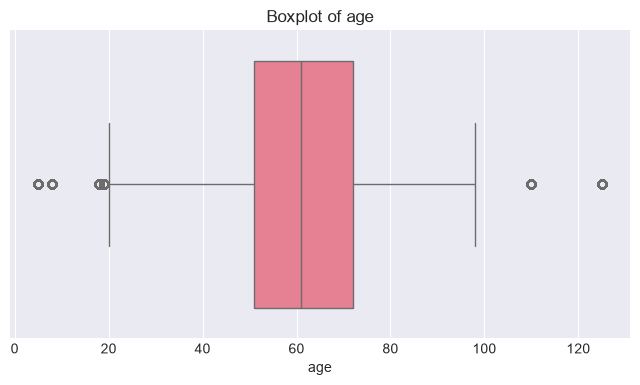

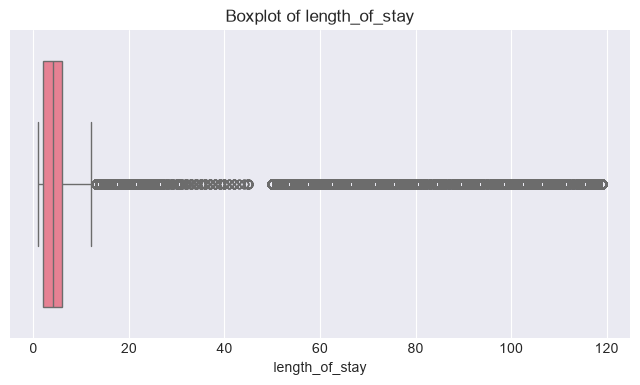

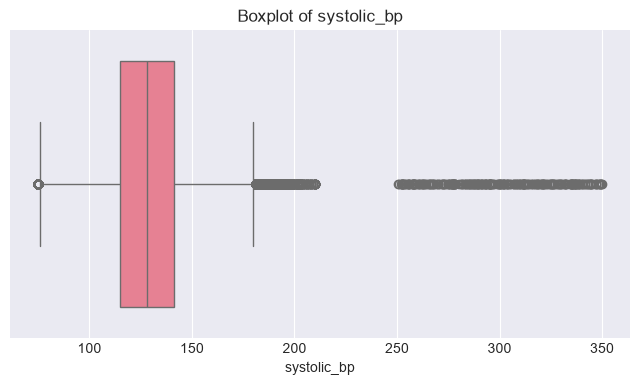

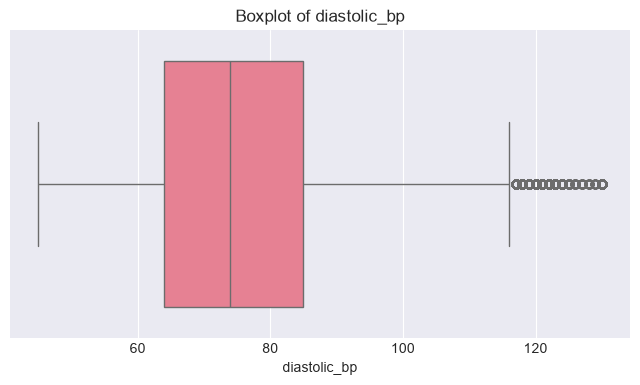

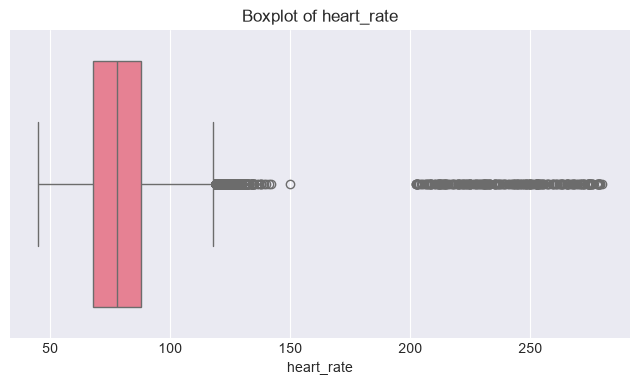

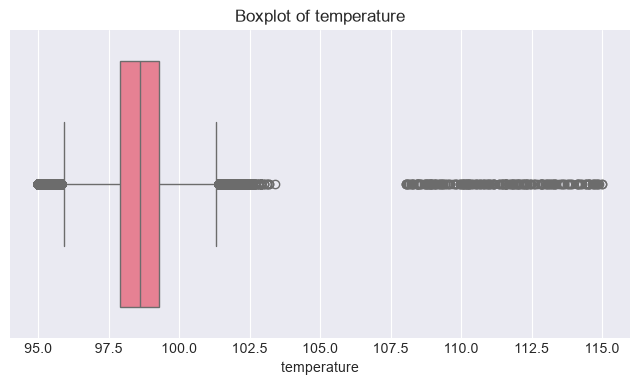

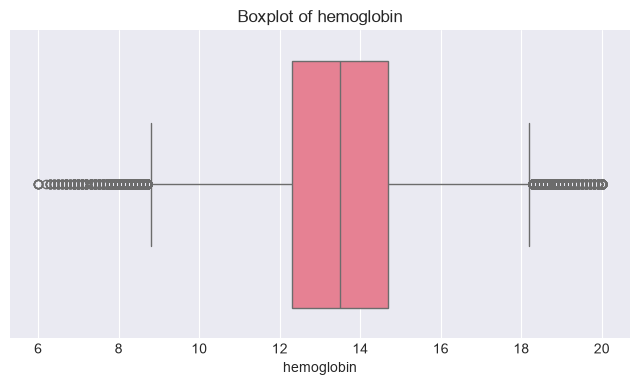

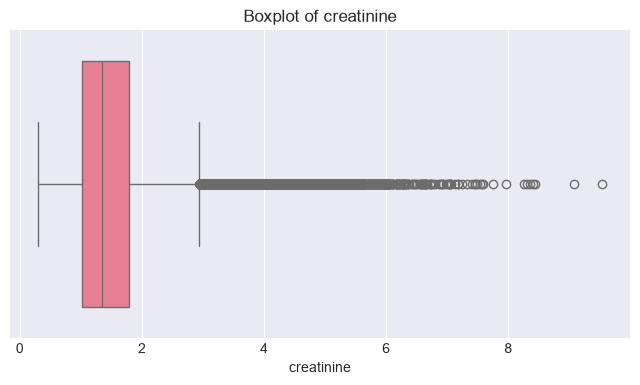

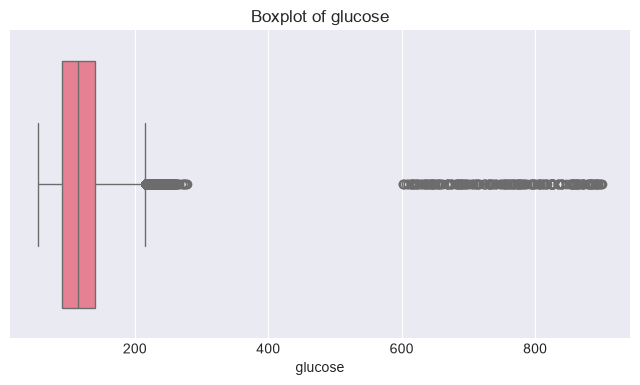

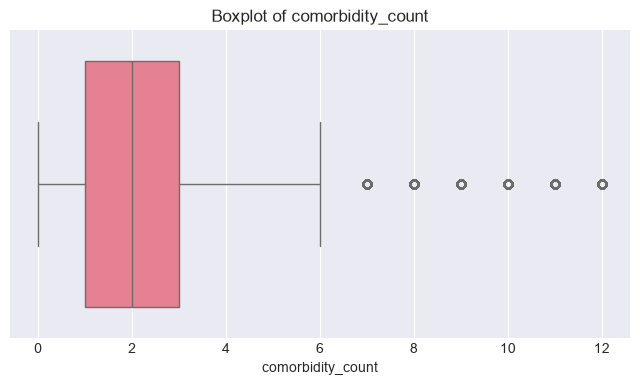

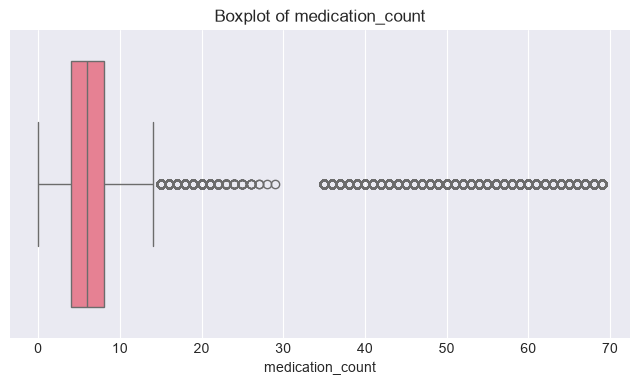

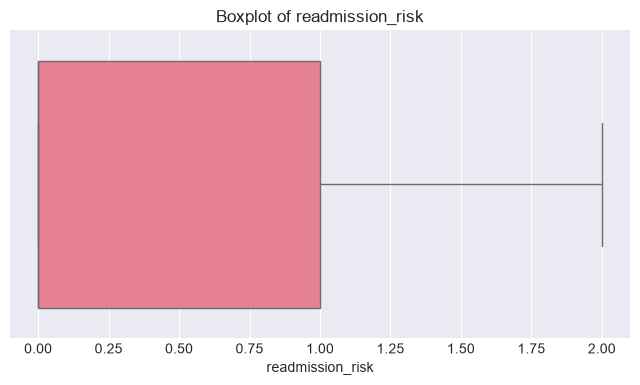

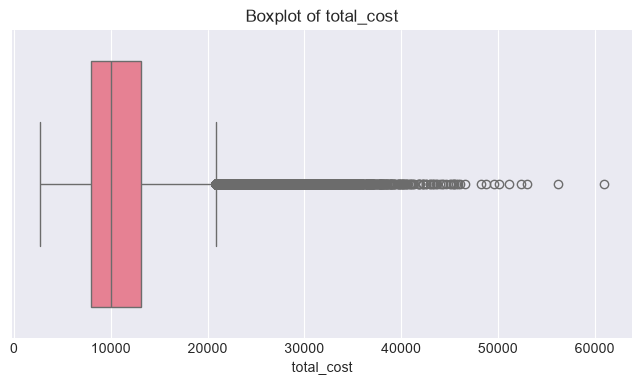

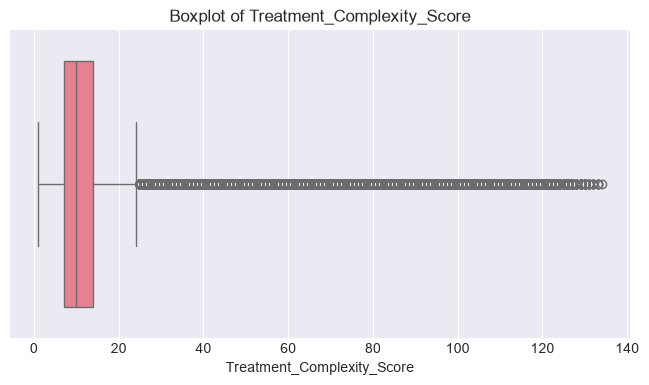

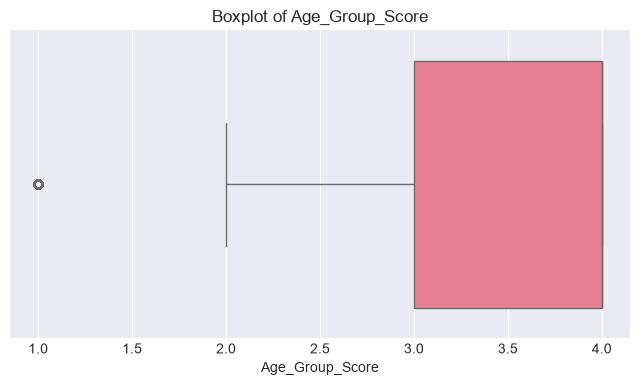

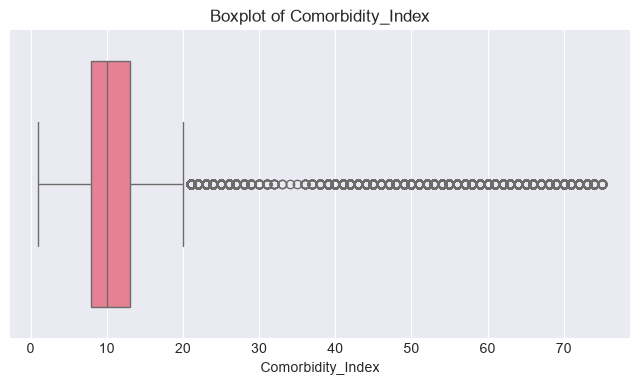

In [76]:

for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col]) #creates boxplot for that col
    plt.title(f'Boxplot of {col}') #tile
    plt.show() #display the graph



In [73]:
outlier_bounds = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower_bound, upper_bound)

    print(f"{col}: Lower = {lower_bound:.2f}, Upper = {upper_bound:.2f}")

age: Lower = 19.50, Upper = 103.50
length_of_stay: Lower = -4.00, Upper = 12.00
systolic_bp: Lower = 76.00, Upper = 180.00
diastolic_bp: Lower = 32.50, Upper = 116.50
heart_rate: Lower = 38.00, Upper = 118.00
temperature: Lower = 95.80, Upper = 101.40
hemoglobin: Lower = 8.70, Upper = 18.30
creatinine: Lower = -0.14, Upper = 2.95
glucose: Lower = 15.00, Upper = 215.00
comorbidity_count: Lower = -2.00, Upper = 6.00
medication_count: Lower = -2.00, Upper = 14.00
readmission_risk: Lower = -1.50, Upper = 2.50
total_cost: Lower = 118.82, Upper = 20899.14
Treatment_Complexity_Score: Lower = -3.50, Upper = 24.50
Age_Group_Score: Lower = 1.50, Upper = 5.50
Comorbidity_Index: Lower = 0.50, Upper = 20.50


In [74]:
outlier_counts = {}

for col in num_cols:
    lower_bound, upper_bound = outlier_bounds[col]

    count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

    outlier_counts[col] = count

    print(f"{col}: {count} potential outliers")



age: 10277 potential outliers
length_of_stay: 25737 potential outliers
systolic_bp: 4090 potential outliers
diastolic_bp: 1896 potential outliers
heart_rate: 1396 potential outliers
temperature: 5491 potential outliers
hemoglobin: 3877 potential outliers
creatinine: 15935 potential outliers
glucose: 1829 potential outliers
comorbidity_count: 9946 potential outliers
medication_count: 15640 potential outliers
readmission_risk: 0 potential outliers
total_cost: 16359 potential outliers
Treatment_Complexity_Score: 29403 potential outliers
Age_Group_Score: 12393 potential outliers
Comorbidity_Index: 14632 potential outliers


Outlier handling decisions:

- Age: Keep the outliers because some values are high, but they may represent elderly patients. No automatic removal was done.
- Length of stay: Keep the outliers because some patients may have long hospital stays. No automatic removal was done.
- Systolic BP: Keep the outliers for now because extreme values may represent genuine clinical observations. No automatic removal was done.
- Diastolic BP: Keep the outliers because they may represent genuine patient measurements.
- Heart rate: Keep the outliers for now because extreme values should be investigated before changing them.
- Temperature: Keep the outliers for now because unusual values should not be removed automatically.
- Hemoglobin: Keep the outliers because they may represent genuine clinical measurements.
- Creatinine: Keep the outliers because high values may occur in patients with serious conditions.
- Glucose: Keep the outliers for now because very high glucose values may represent genuine patient measurements. They should not be removed automatically.
- Comorbidity count: Keep the outliers because patients can have multiple health conditions.
- Medication count: Keep the outliers because patients with complex conditions may take many medications.
- Readmission risk: No outliers were found using the IQR method, so no action is needed.
- Total cost: Keep the outliers because higher treatment costs may be genuine for patients requiring more care.

In [70]:
df["glucose"].sort_values(ascending=False).head()

334642    899.940868
438797    898.408872
373079    897.913325
363249    897.418582
124902    894.750852
Name: glucose, dtype: float64

In [ ]:
df["length_of_stay"].sort_values(ascending=False).head()

381493    119
316748    119
304917    119
375482    119
326983    119
Name: length_of_stay, dtype: int64

In [ ]:
df["age"].sort_values(ascending=False).head()

336614    125
469306    125
200659    125
305016    125
34839     125
Name: age, dtype: int64

In [ ]:
df["systolic_bp"].sort_values(ascending=False).head()

352019    349.888828
464470    349.450151
138297    349.294071
473584    349.090791
388980    348.824374
Name: systolic_bp, dtype: float64

In [ ]:
df["diastolic_bp"].sort_values(ascending=False).head()

499736    130.0
226722    130.0
452313    130.0
204950    130.0
416633    130.0
Name: diastolic_bp, dtype: float64

In [ ]:
df["heart_rate"].sort_values(ascending=False).head()

493591    279.760584
482286    279.084058
146956    278.998095
2703      278.749093
365617    278.736500
Name: heart_rate, dtype: float64

## Task 2.3: Standardize Categorical Values

**YOUR TASK:** Check for inconsistent formatting (e.g., extra spaces, mixed case) and standardize.

In [ ]:
print(df["gender"].unique())
print(df["admission_type"].unique())
print(df["primary_diagnosis"].unique())
print(df["hospital_department"].unique())
print(df["insurance_type"].unique())

<StringArray>
['M', 'F']
Length: 2, dtype: str
<StringArray>
['Trauma', 'Elective', 'Urgent', 'Emergency']
Length: 4, dtype: str
<StringArray>
['Neurological', 'Gastrointestinal', 'Orthopedic', 'Respiratory', 'Cardiovascular']
Length: 5, dtype: str
<StringArray>
['Emergency', 'General Medicine', 'Pediatrics', 'ICU', 'Cardiology', 'Surgery']
Length: 6, dtype: str
<StringArray>
['Other', 'Self-Pay', 'Medicaid', 'Private', 'Medicare']
Length: 5, dtype: str


Observation: The categorical columns were checked for inconsistent formatting, extra spaces, and mixed capitalization. The values appear consistently formatted, so no standardization was required.

## Task 2.4: Date Handling

**YOUR TASK:**
1. Convert date columns to datetime
2. Verify Length of Stay matches the date difference

In [ ]:
df["admission_date"] = pd.to_datetime(df["admission_date"])



In [ ]:
df["admission_date"].dtype

dtype('<M8[us]')

In [ ]:
df["discharge_date"] = pd.to_datetime(df["discharge_date"])

In [ ]:
df["discharge_date"].dtype

dtype('<M8[us]')

In [ ]:
#length of the day matches the difference
df["calculated_stay"] = (
    df["discharge_date"] - df["admission_date"]
).dt.days

In [ ]:
df[["length_of_stay", "calculated_stay"]].head()

,length_of_stay,calculated_stay
0,4,4
1,4,4
2,2,2
3,5,5
4,9,9


In [ ]:
(df["length_of_stay"] != df["calculated_stay"]).sum()


np.int64(8441)

In [ ]:
df[df["length_of_stay"] != df["calculated_stay"]][
    ["admission_date", "discharge_date", "length_of_stay", "calculated_stay"]
].head(10)

,admission_date,discharge_date,length_of_stay,calculated_stay
104,2022-04-13,2022-04-21,83,8
126,2022-12-27,2022-12-31,68,4
131,2024-06-05,2024-06-08,55,3
265,2022-11-30,2022-12-04,104,4
370,2024-02-18,2024-02-19,98,1
563,2024-02-13,2024-02-17,110,4
660,2022-12-06,2022-12-14,108,8
695,2022-07-13,2022-07-18,75,5
764,2023-10-26,2023-10-30,86,4
847,2022-05-27,2022-05-30,105,3


In [ ]:
df["stay_difference"] = (
    df["length_of_stay"] - df["calculated_stay"]
)

df["stay_difference"].describe()

count    500000.000000
mean          1.353862
std          10.667521
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max         118.000000
Name: stay_difference, dtype: float64

In [ ]:
df.sort_values("stay_difference", ascending=False)[
    ["length_of_stay", "calculated_stay", "stay_difference"]
].head(10)

,length_of_stay,calculated_stay,stay_difference
323593,119,1,118
383093,119,1,118
301742,119,1,118
204563,119,1,118
74974,119,1,118
378248,119,1,118
395858,119,1,118
234352,119,1,118
58230,119,1,118
224226,119,1,118


In [ ]:
df.drop(columns=["calculated_stay", "stay_difference"], inplace=True)

Observation: The recorded length_of_stay was compared with the difference between admission and discharge dates. 8,441 records showed mismatches. Some mismatches were substantial, such as 119 recorded days versus 1 calculated day. These records were identified for further investigation rather than automatically removed.

## Task 2.5: Check for Duplicates

**YOUR TASK:** Identify and remove duplicate records.

In [ ]:
df.duplicated().sum()


np.int64(0)

Observation:No duplicate records were found

## Task 2.6: Validate Cleaning with D-Tale

**YOUR TASK:** Reload the cleaned dataset in D-Tale and verify all issues are resolved.

In [ ]:
df.isnull().sum()


patient_id             0
age                    0
gender                 0
admission_type         0
primary_diagnosis      0
hospital_department    0
length_of_stay         0
systolic_bp            0
diastolic_bp           0
heart_rate             0
temperature            0
hemoglobin             0
creatinine             0
glucose                0
comorbidity_count      0
medication_count       0
insurance_type         0
admission_date         0
discharge_date         0
readmission_risk       0
total_cost             0
dtype: int64

In [ ]:
df.dtypes

patient_id                        str
age                             int64
gender                            str
admission_type                    str
primary_diagnosis                 str
hospital_department               str
length_of_stay                  int64
systolic_bp                   float64
diastolic_bp                  float64
heart_rate                    float64
temperature                   float64
hemoglobin                    float64
creatinine                    float64
glucose                       float64
comorbidity_count               int64
medication_count                int64
insurance_type                    str
admission_date         datetime64[us]
discharge_date         datetime64[us]
readmission_risk                int64
total_cost                    float64
dtype: object

Observation: Data types were validated after cleaning. Numerical columns have appropriate numeric types, categorical columns are stored as strings, and admission and discharge dates are stored as datetime values.

### 📝 Cleaning Summary

**YOUR TASK:** Summarize what you cleaned.

- Rows before cleaning: 500,000
- Rows after cleaning:500,000
- Columns modified: 7 clinical measurement columns,admission_date,discharge_date
- Missing values: Missing values in the 7 clinical  measurement columns were filled using the median of each col 
- Categorial values: No obvious formatting inconsistencies were found, so no changes were required
- dates: admission and discharge dates were converted to datetime format
- Length of stay: 
- Duplicates: No duplicate records were found
- Final validation:Missing value counts were  and datatypes are verified.


---
# 📊 Section 4: Univariate Analysis

**Phase 3** — Analyze each variable individually.

## Task 3.1: Numerical Variables — Histograms

**YOUR TASK:** Create histograms for Age, Billing Amount, Length of Stay, Previous Admissions, and Medication Count.

In [ ]:
num_cols=df.select_dtypes(include=["int64","float64"]).columns
print(list(num_cols))

['age', 'length_of_stay', 'systolic_bp', 'diastolic_bp', 'heart_rate', 'temperature', 'hemoglobin', 'creatinine', 'glucose', 'comorbidity_count', 'medication_count', 'readmission_risk', 'total_cost']


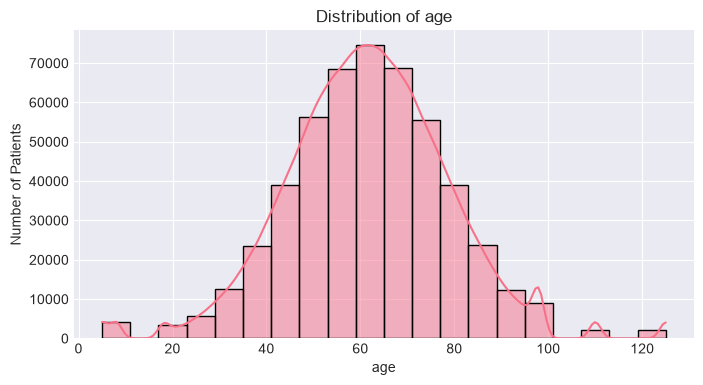

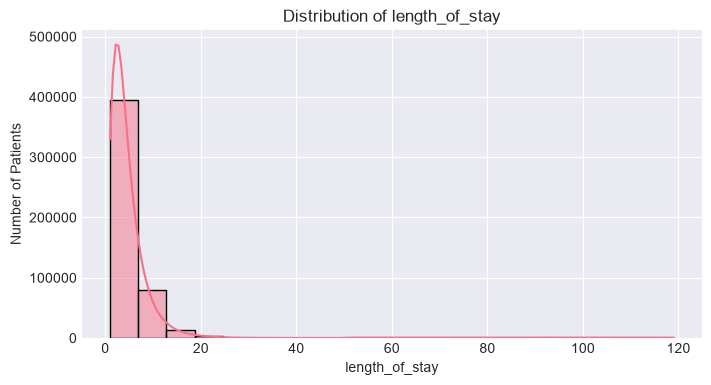

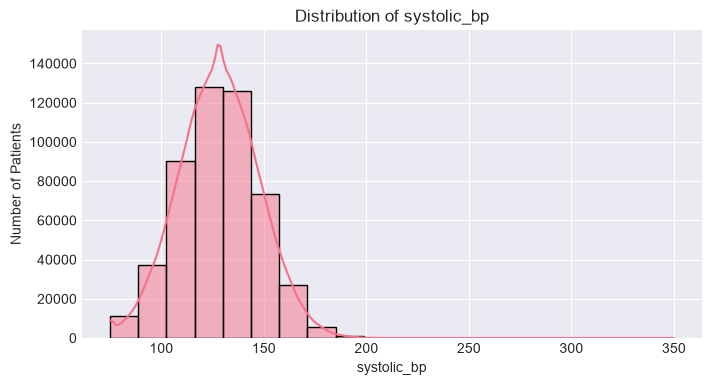

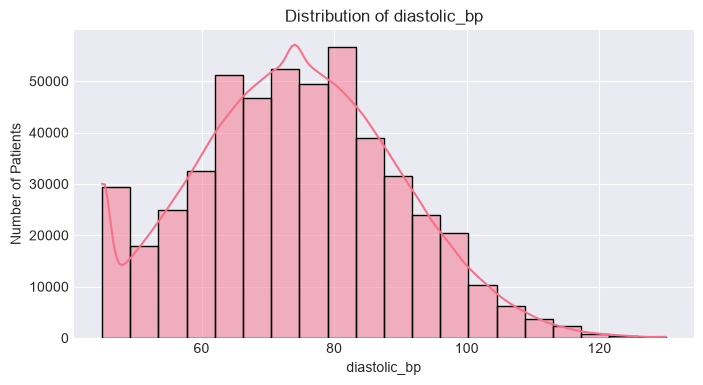

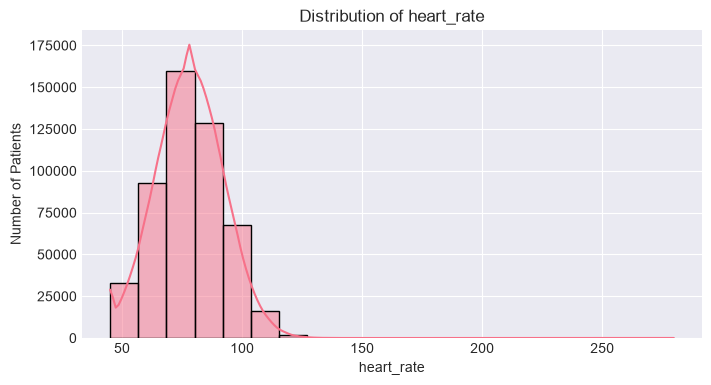

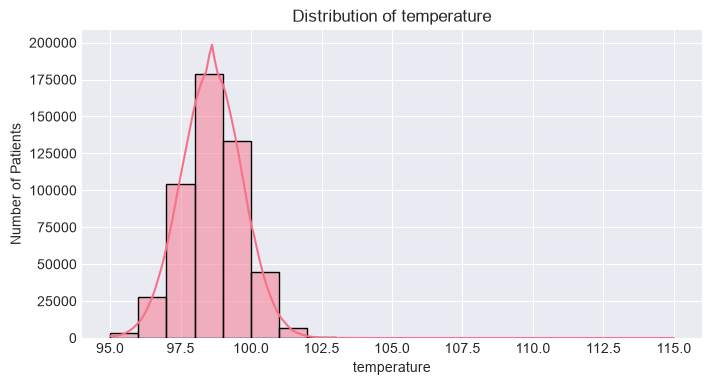

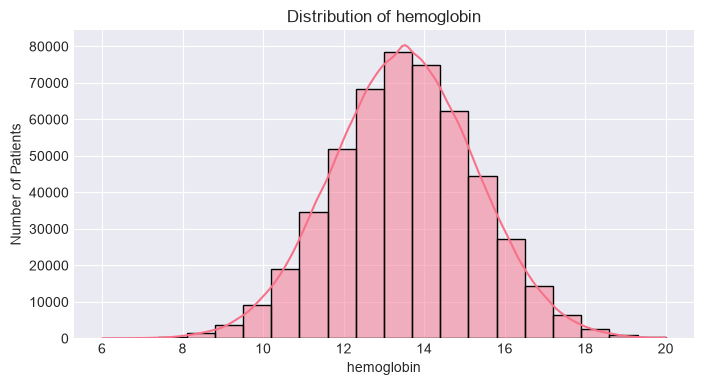

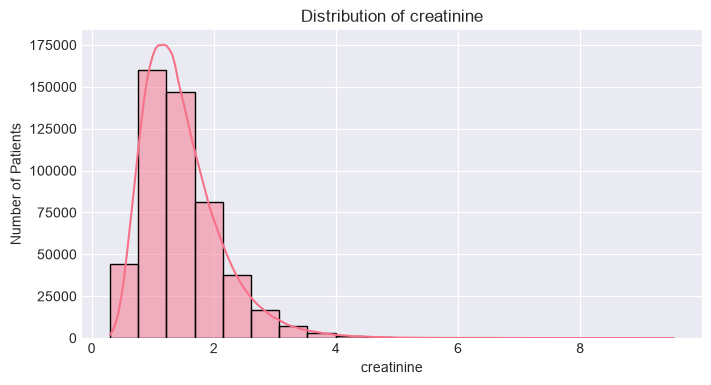

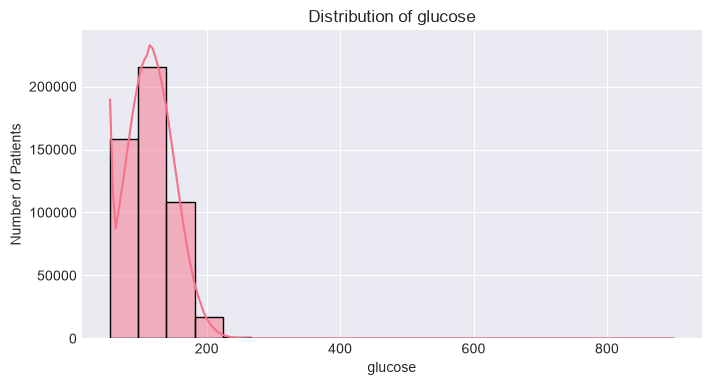

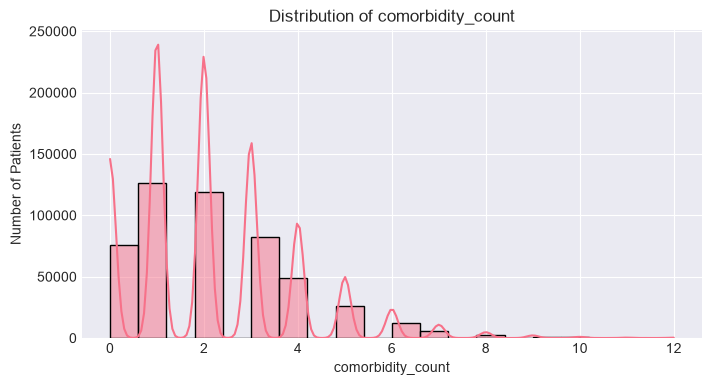

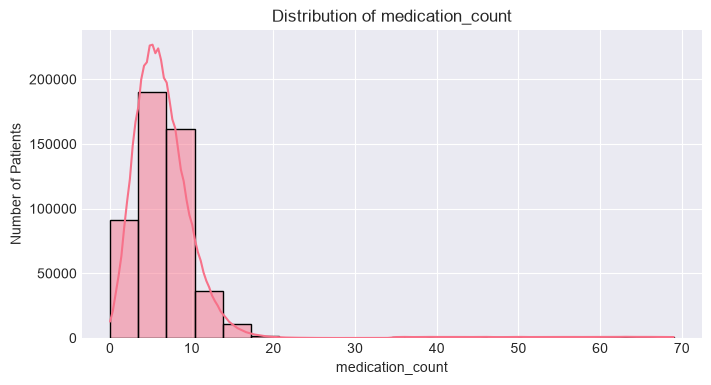

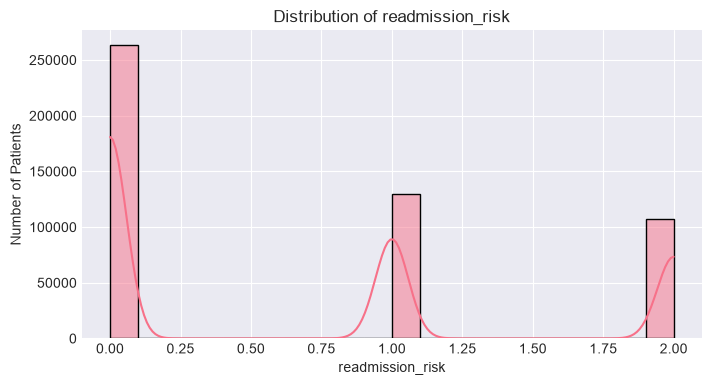

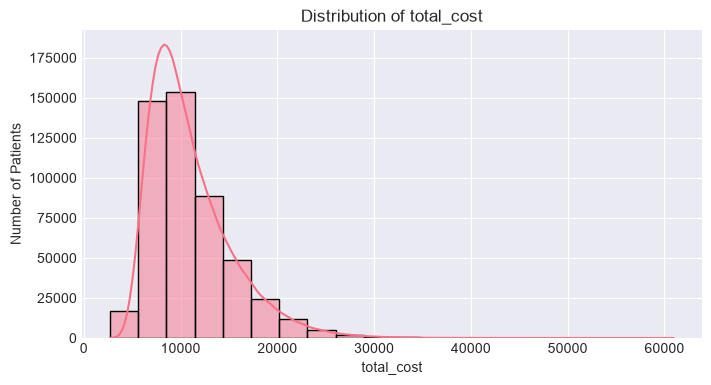

In [ ]:
for col in num_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(data=df, x=col, kde=True, bins=20)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of Patients")
    plt.show()
# HINT: Use sns.histplot() with kde=True



## Task 3.2: Numerical Variables — Boxplots

**YOUR TASK:** Create boxplots for Billing Amount, Length of Stay, and Age.

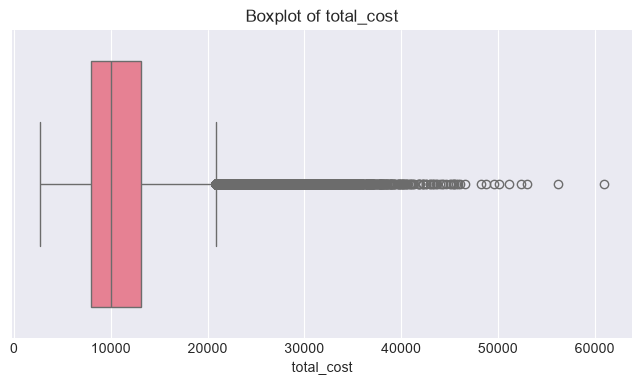

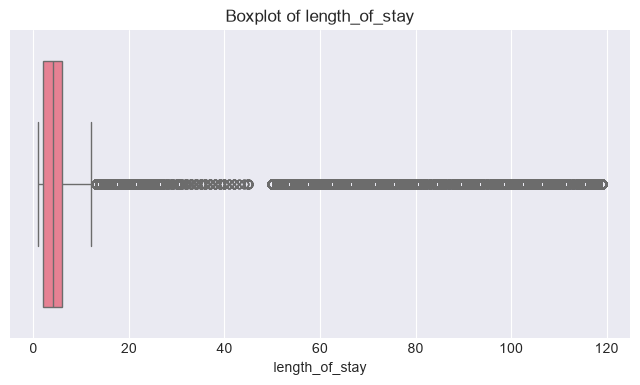

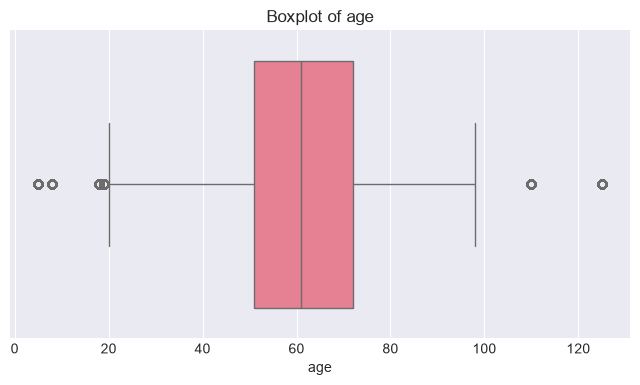

In [ ]:
boxplot_cols = ["total_cost", "length_of_stay", "age"]

for col in boxplot_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()


## Task 3.3: Summary Statistics Table

**YOUR TASK:** Create a formatted summary table (mean, median, mode, std, quartiles) for numerical columns.

In [ ]:
summary_table = pd.DataFrame({
    "Mean": df[num_cols].mean(),
    "Median": df[num_cols].median(),
    "Mode": df[num_cols].mode().iloc[0],
    "Standard Deviation": df[num_cols].std(),
    "Q1": df[num_cols].quantile(0.25),
    "Q3": df[num_cols].quantile(0.75)
})

summary_table


,Mean,Median,Mode,Standard Deviation,Q1,Q3
age,61.450434,61.00,61.00,17.067469,51.00,72.00
length_of_stay,5.848698,4.00,2.00,11.213647,2.00,6.00
systolic_bp,128.094571,128.00,128.00,19.966993,115.00,141.00
diastolic_bp,74.417350,74.00,45.00,15.352589,64.00,85.00
heart_rate,78.159240,78.00,78.00,14.584793,68.00,88.00
temperature,98.605860,98.60,98.60,1.109671,97.90,99.30
hemoglobin,13.502829,13.50,13.50,1.778610,12.30,14.70
creatinine,1.473143,1.35,1.35,0.648990,1.02,1.79
glucose,116.042695,115.00,55.00,38.037042,90.00,140.00
comorbidity_count,2.172898,2.00,1.00,1.708277,1.00,3.00


## Task 3.4: Categorical Variables — Bar Charts

**YOUR TASK:** Create bar charts for Gender, Medical Condition (top 10), Admission Type, and Insurance Type.

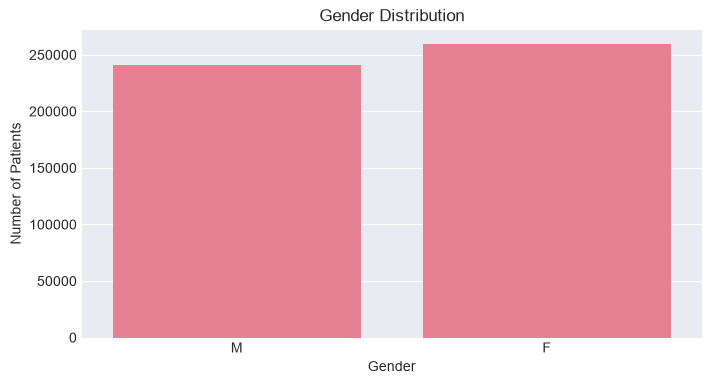

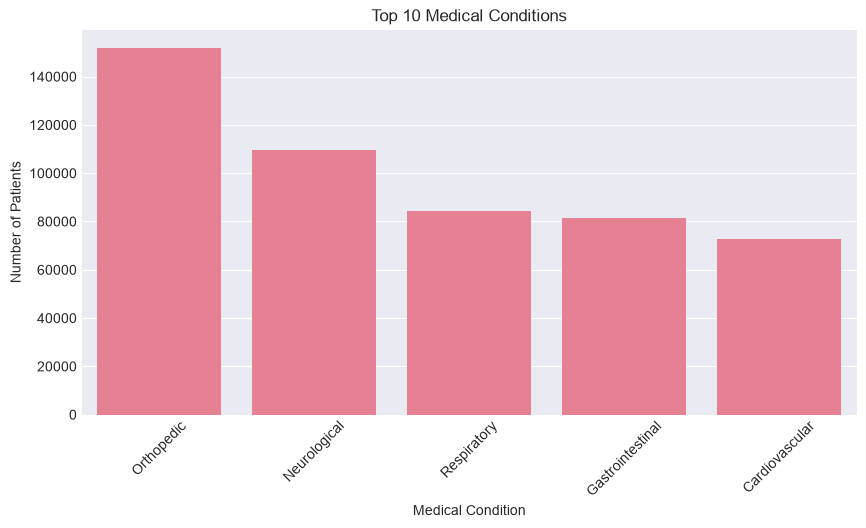

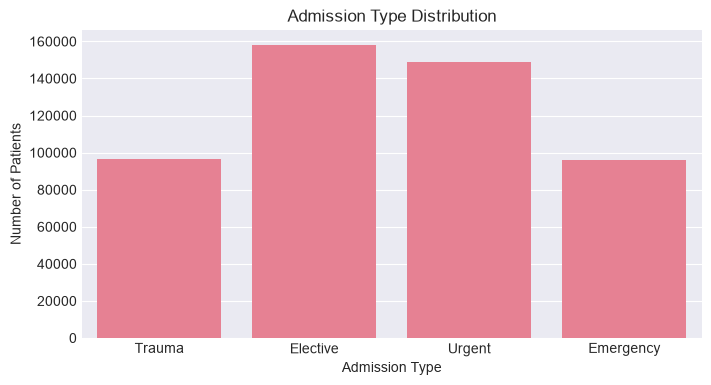

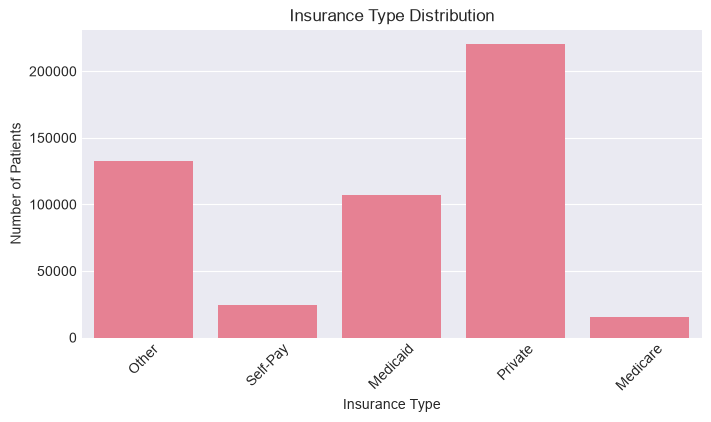

In [17]:
# Gender
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="gender")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()


# Medical Condition - Top 10
top_conditions = df["primary_diagnosis"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_conditions.index, y=top_conditions.values)
plt.title("Top 10 Medical Conditions")
plt.xlabel("Medical Condition")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()


# Admission Type
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="admission_type")
plt.title("Admission Type Distribution")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")
plt.show()


# Insurance Type
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="insurance_type")
plt.title("Insurance Type Distribution")
plt.xlabel("Insurance Type")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.show()



## Task 3.5: Categorical Variables — Pie Charts

**YOUR TASK:** Create pie charts for Admission Type and Insurance Type with percentages.

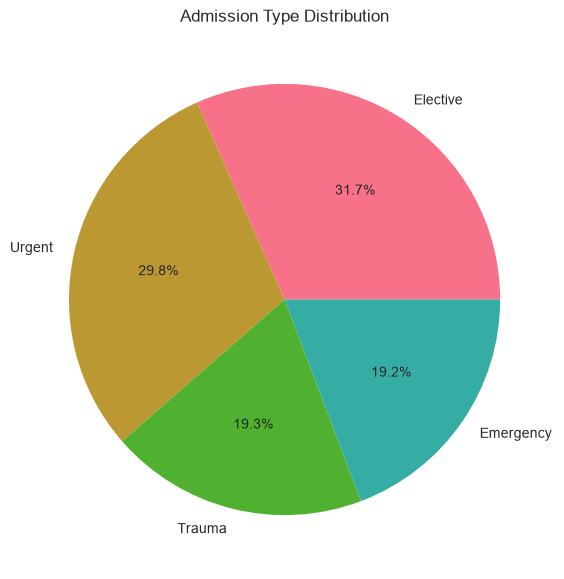

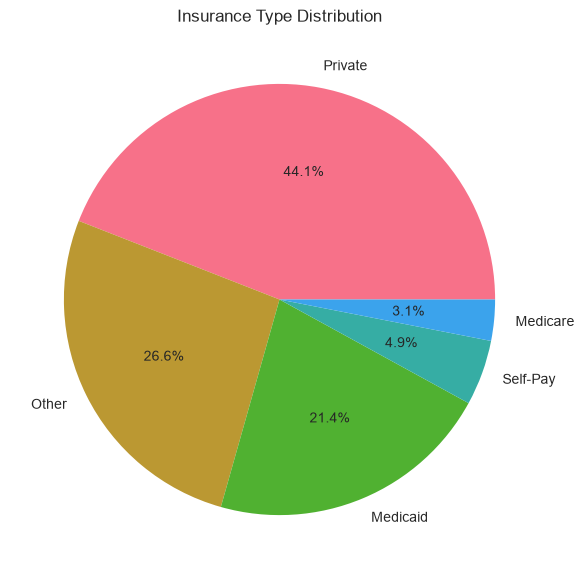

In [ ]:
 # Admission Type
admission_counts = df["admission_type"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    admission_counts,
    labels=admission_counts.index,
    autopct="%1.1f%%"
)
plt.title("Admission Type Distribution")
plt.show()


# Insurance Type
insurance_counts = df["insurance_type"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    insurance_counts,
    labels=insurance_counts.index,
    autopct="%1.1f%%" #shows percentage in each slice
)
plt.title("Insurance Type Distribution")
plt.show()



## Task 3.6: Target Variable — Readmission Risk

**YOUR TASK:** Analyze the distribution of the Readmission Risk variable.

2026-09-19 22:33:31,125 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-09-19 22:33:31,699 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


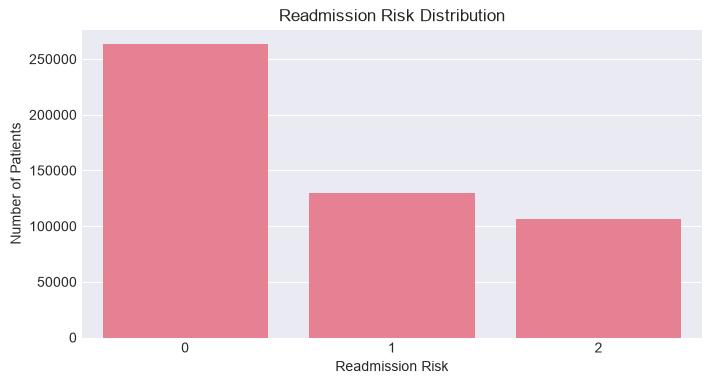

In [19]:
plt.figure(figsize=(8, 4))

sns.countplot(data=df, x="readmission_risk")

plt.title("Readmission Risk Distribution")
plt.xlabel("Readmission Risk")
plt.ylabel("Number of Patients")
plt.show()


### 📝 Univariate Observations

**YOUR TASK:** Write observations for each visualization above.

1. Readmission Risk 0 has the highest no.of patients 
2. Readmission Risk 1 has fewer patients than Readmission Risk 0 but more than risk 2.(moderate)
3. Readmission Risk 3 has lowest number of patients

---
# 🔗 Section 5: Bivariate & Multivariate Analysis

**Phase 4** — Explore relationships between variables.

## Task 4.1: Categorical vs Categorical

**YOUR TASK:** Create grouped/stacked bar charts for:
- Admission Type vs Readmission Risk
- Gender vs Medical Condition
- Insurance Type vs Admission Type

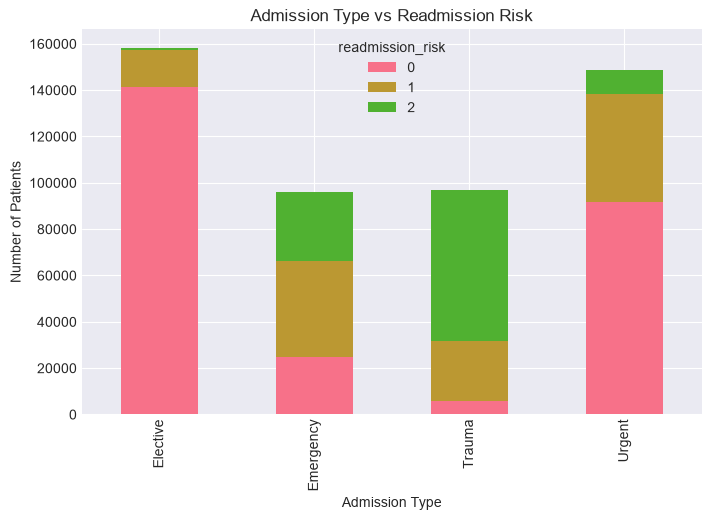

In [21]:
group1=pd.crosstab(df["admission_type"],df["readmission_risk"])
group1.plot(kind="bar", stacked=True,figsize=(8,5))
plt.title("Admission Type vs Readmission Risk")
plt.xlabel("Admission Type")
plt.ylabel("Number of Patients")
plt.show()



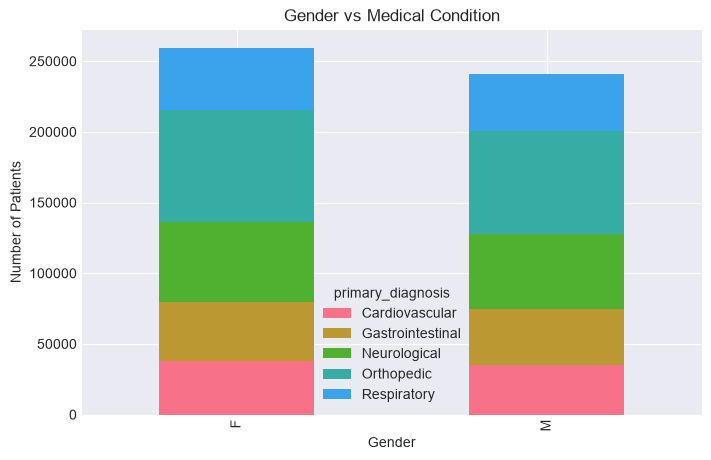

In [22]:
group2=pd.crosstab(df["gender"],df["primary_diagnosis"])
group2.plot(kind="bar", stacked=True,figsize=(8,5))
plt.title("Gender vs Medical Condition")
plt.xlabel("Gender")
plt.ylabel("Number of Patients")
plt.show()

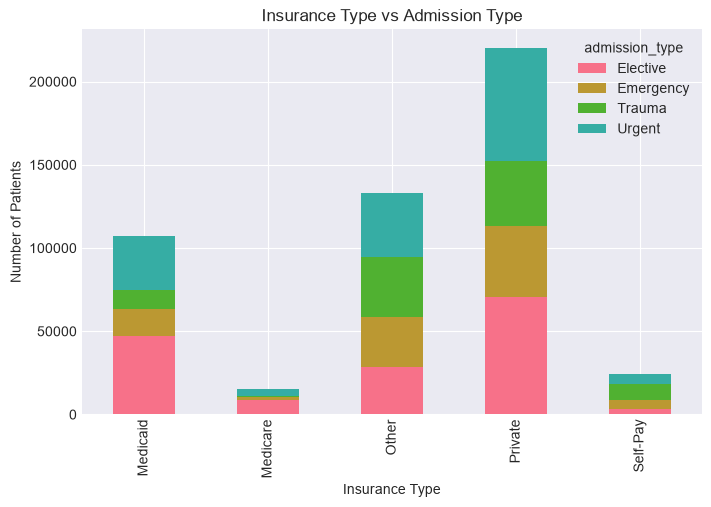

In [23]:
# Insurance Type vs Admission Type
table3 = pd.crosstab(df["insurance_type"], df["admission_type"])

table3.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Insurance Type vs Admission Type")
plt.xlabel("Insurance Type")
plt.ylabel("Number of Patients")
plt.show()

## Task 4.2: Categorical vs Numerical

**YOUR TASK:** Create boxplots/violin plots for:
- Medical Condition vs Billing Amount
- Admission Type vs Length of Stay
- Gender vs Billing Amount
- Readmission Risk vs Billing Amount

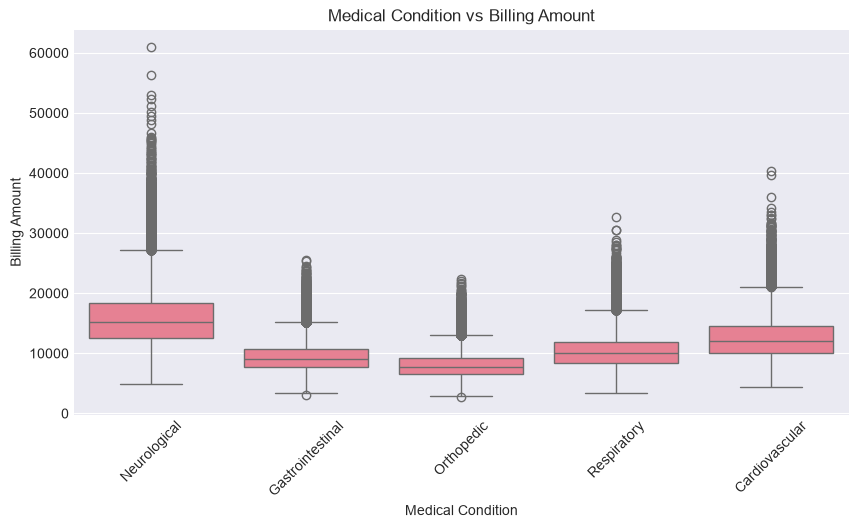

In [24]:
# 1. Medical Condition vs Billing Amount
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="primary_diagnosis", y="total_cost")
plt.title("Medical Condition vs Billing Amount")
plt.xlabel("Medical Condition")
plt.ylabel("Billing Amount")
plt.xticks(rotation=45)
plt.show()


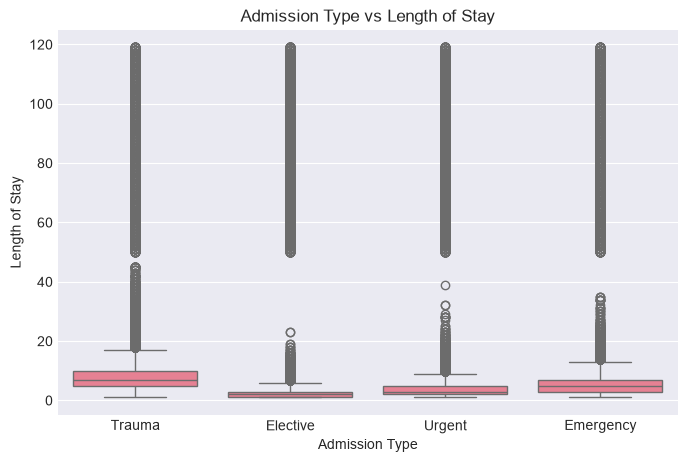

In [25]:
# 2. Admission Type vs Length of Stay
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="admission_type", y="length_of_stay")
plt.title("Admission Type vs Length of Stay")
plt.xlabel("Admission Type")
plt.ylabel("Length of Stay")
plt.show()

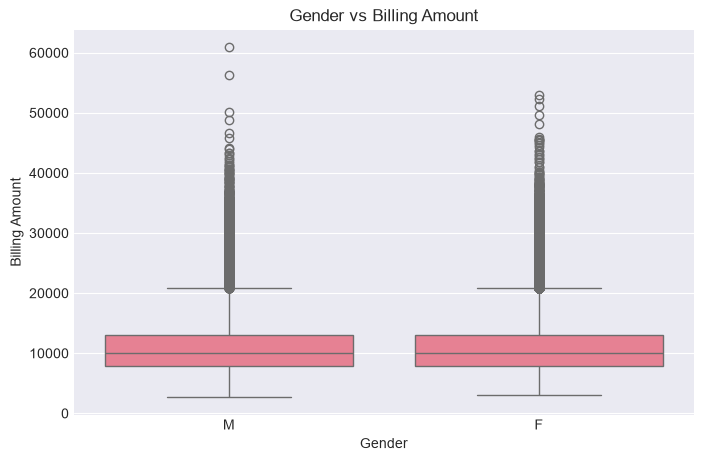

In [26]:
# 3. Gender vs Billing Amount
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="gender", y="total_cost")
plt.title("Gender vs Billing Amount")
plt.xlabel("Gender")
plt.ylabel("Billing Amount")
plt.show()

2026-09-19 22:54:30,488 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-09-19 22:54:31,070 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


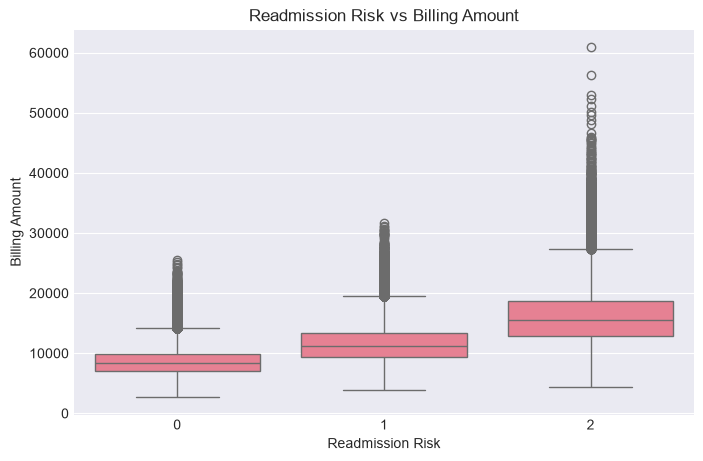

In [27]:
# 4. Readmission Risk vs Billing Amount
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="readmission_risk", y="total_cost")
plt.title("Readmission Risk vs Billing Amount")
plt.xlabel("Readmission Risk")
plt.ylabel("Billing Amount")
plt.show()

## Task 4.3: Numerical vs Numerical — Scatter Plots

**YOUR TASK:** Create scatter plots:
- Age vs Billing Amount (colored by Readmission Risk)
- Length of Stay vs Billing Amount
- Age vs Length of Stay

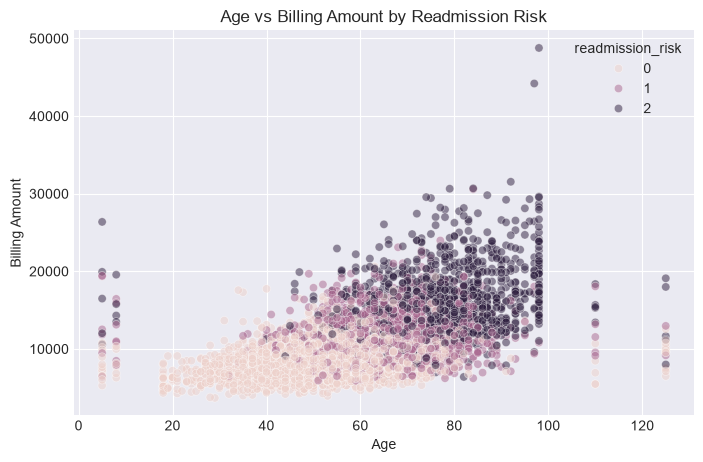

In [28]:
sample_df = df.sample(5000)

# 1. Age vs Billing Amount, colored by Readmission Risk
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="age",
    y="total_cost",
    hue="readmission_risk",
    alpha=0.5
)
plt.title("Age vs Billing Amount by Readmission Risk")
plt.xlabel("Age")
plt.ylabel("Billing Amount")
plt.show()



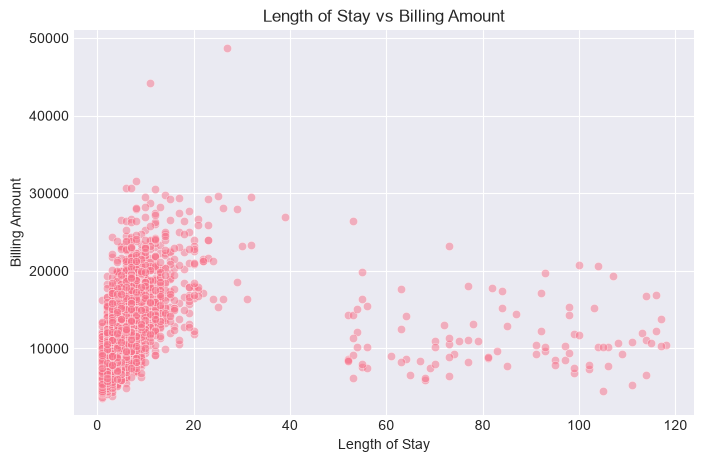

In [29]:
# 2. Length of Stay vs Billing Amount
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="length_of_stay",
    y="total_cost",
    alpha=0.5
)
plt.title("Length of Stay vs Billing Amount")
plt.xlabel("Length of Stay")
plt.ylabel("Billing Amount")
plt.show()

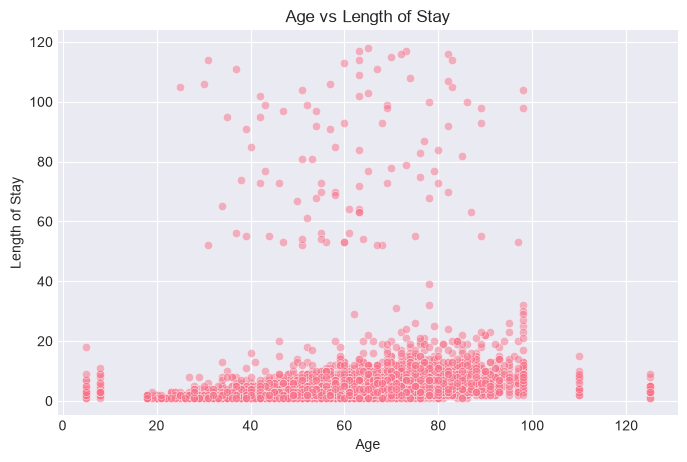

2026-09-19 23:03:19,175 - INFO     - Executing shutdown due to inactivity...
2026-09-19 23:03:23,403 - INFO     - Executing shutdown...
2026-09-19 23:03:23,407 - INFO     - Not running with the Werkzeug Server, exiting by searching gc for BaseWSGIServer


In [ ]:
# 3. Age vs Length of Stay
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=sample_df,
    x="age",
    y="length_of_stay",
    alpha=0.5
)
plt.title("Age vs Length of Stay")
plt.xlabel("Age")
plt.ylabel("Length of Stay")
plt.show()

## Task 4.4: Correlation Heatmap

**YOUR TASK:** Create a correlation heatmap for numerical variables and identify the top 3 positive and negative correlations.

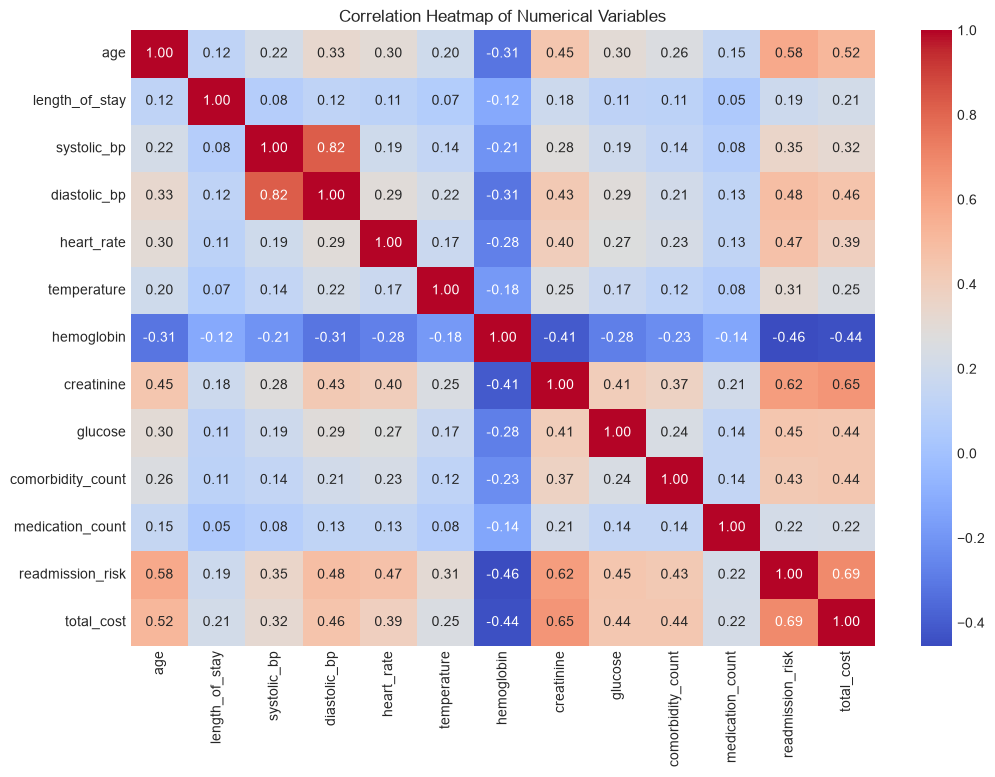

In [33]:
# Correlation matrix for numerical variables
corr = df.corr(numeric_only=True)

# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

In [ ]:
print("Top 3 Positive Correlations:")
print("Admission Risk & Total Cost: 0.69")
print("Creatinine & Total Cost: 0.65")
print("Creatinine & Admission Risk: 0.62")

print("\nTop 3 Negative Correlations:")
print("Hemoglobin & Admission Risk: -0.46")
print("Hemoglobin & Total Cost: -0.46")
print("Hemoglobin & Creatinine: -0.41")

Top 3 Positive Correlations:
Admission Risk & Total Cost: 0.69
Creatinine & Total Cost: 0.65
Creatinine & Admission Risk: 0.62

Top 3 Negative Correlations:
Hemoglobin & Admission Risk: -0.46
Hemoglobin & Total Cost: -0.46
Hemoglobin & Creatinine: -0.41


## Task 4.5: Multivariate Analysis — Pairplot

**YOUR TASK:** Create a pairplot for Age, Billing Amount, Length of Stay, and Previous Admissions, colored by Readmission Risk.

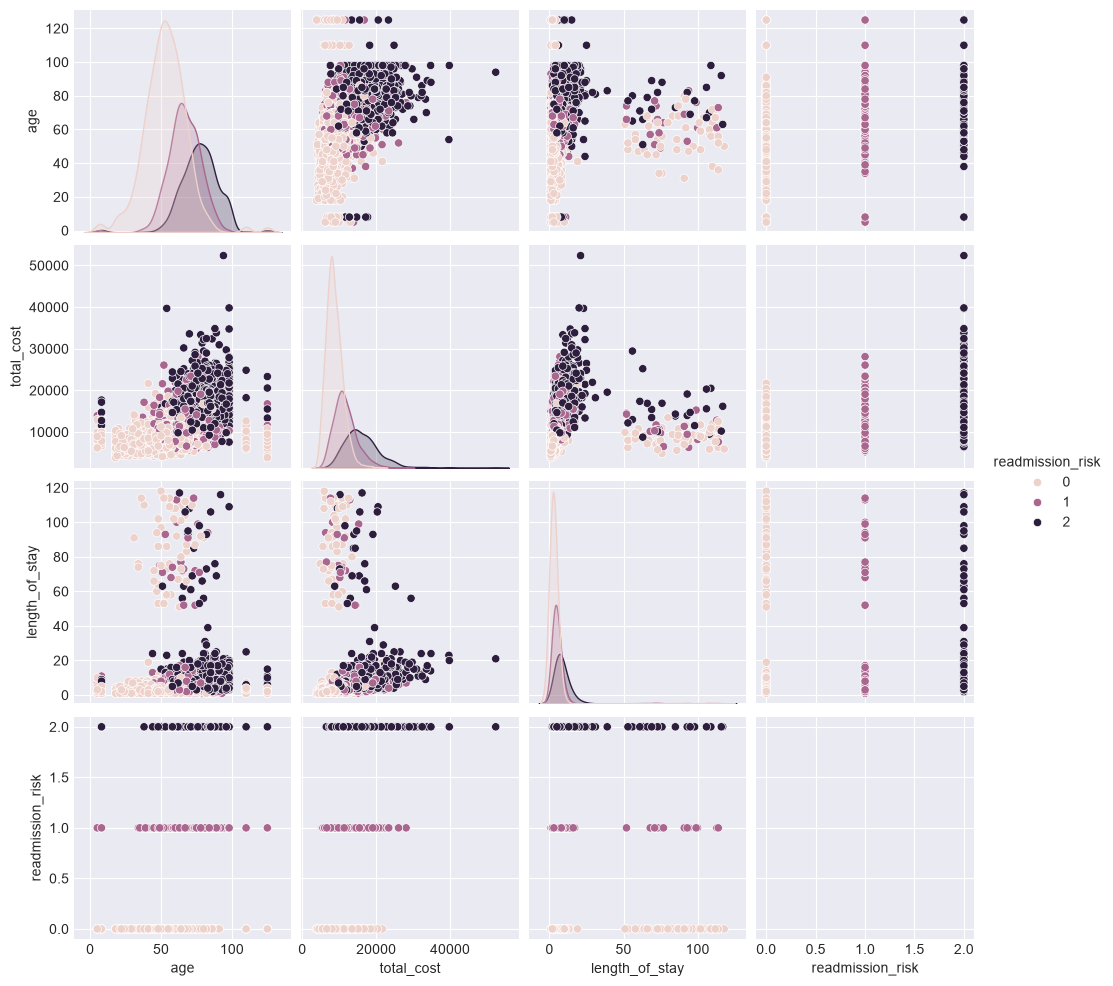

In [38]:
sample_df = df.sample(5000)

sns.pairplot(
    sample_df,
    vars=["age", "total_cost", "length_of_stay", "readmission_risk"],
    hue="readmission_risk"
)

plt.show()



### 📝 Bivariate Observations

**YOUR TASK:** Document key relationships discovered.

1. Older patients generally have higher readmission risk
2. Patients with higher readmission risk have higher total cost
3. Patients with l0onger hospital stays generally have higher total cost

---
# ⚙️ Section 6: Feature Engineering

**Phase 5** — Create new features that add analytical value.

## Task 5.1: Create Age Groups

**YOUR TASK:** Create an `Age_Group` column with categories: Young Adult (18-30), Adult (31-45), Middle Age (46-60), Senior (60+).

In [39]:
df["Age_Group"] = pd.cut(
    df["age"],
    bins=[17, 30, 45, 60, 125],
    labels=["Young Adult", "Adult", "Middle Age", "Senior"]
)

df["Age_Group"].value_counts()



Age_Group
Senior         262278
Middle Age     157080
Adult           64130
Young Adult     12393
Name: count, dtype: int64

In [56]:
df["Age_Group"].isna().sum()

np.int64(4119)

## Task 5.2: Create Cost Categories

**YOUR TASK:** Create a `Cost_Category` column (Low, Medium, High) based on Billing Amount percentiles.

In [41]:
df["total_cost"].quantile([0.33, 0.66])


0.33     8543.1902
0.66    11749.8734
Name: total_cost, dtype: float64

In [42]:
df["Cost_Category"] = pd.cut(
    df["total_cost"],
    bins=[-float("inf"), 8543.1902, 11749.8734, float("inf")],
    labels=["Low", "Medium", "High"]
)

df["Cost_Category"].value_counts()

Cost_Category
High      170000
Low       165000
Medium    165000
Name: count, dtype: int64

In [43]:
df["Cost_Category"].value_counts().sum()

np.int64(500000)

## Task 5.3: Create Stay Categories

**YOUR TASK:** Create a `Stay_Category` column: Short (≤3 days), Medium (4-7 days), Long (>7 days).

In [44]:
df["Stay_Category"] = pd.cut(
    df["length_of_stay"],
    bins=[0, 3, 7, float("inf")],
    labels=["Short", "Medium", "Long"]
)

df["Stay_Category"].value_counts()



Stay_Category
Short     241999
Medium    178431
Long       79570
Name: count, dtype: int64

In [46]:
df["Stay_Category"].value_counts().sum()

np.int64(500000)

## Task 5.4: Create Comorbidity Index

**YOUR TASK:** Create a composite score from Previous Admissions, Medication Count, and Age Group.

In [66]:
# Give a score to each age group
age_scores = {
    "Young Adult": 1,
    "Adult": 2,
    "Middle Age": 3,
    "Senior": 4
}

# Convert age groups into numerical scores
df["Age_Group_Score"] = pd.to_numeric(
    df["Age_Group"].map(age_scores),
    errors="coerce"
)

# Create Comorbidity Index
# Combines age score, medication count, and readmission risk
df["Comorbidity_Index"] = (
    df["Age_Group_Score"]
    + df["medication_count"]
    + df["readmission_risk"]
)

# Check the result
df[[
    "Age_Group",
    "Age_Group_Score",
    "medication_count",
    "readmission_risk",
    "Comorbidity_Index"
]].head()


,Age_Group,Age_Group_Score,medication_count,readmission_risk,Comorbidity_Index
0,Middle Age,3.0,6,1,10.0
1,Middle Age,3.0,3,0,6.0
2,Senior,4.0,7,0,11.0
3,Senior,4.0,7,0,11.0
4,Middle Age,3.0,10,0,13.0


## Task 5.5: Create Treatment Complexity Score

**YOUR TASK:** Combine Medication Count and Length of Stay into a single score.

In [54]:
df["Treatment_Complexity_Score"]=(df["medication_count"]+df["length_of_stay"])



In [55]:
df[["medication_count","length_of_stay","Treatment_Complexity_Score"]].head()

,medication_count,length_of_stay,Treatment_Complexity_Score
0,6,4,10
1,3,4,7
2,7,2,9
3,7,5,12
4,10,9,19


### 📝 Feature Engineering Notes

**YOUR TASK:** Explain the rationale for each new feature.

- Age_Group: To group patients into meaningful age categories and make it easier to compare healthcare patterns across different age groups.
- Cost_Category: To divide patients into Low, Medium, and High cost groups so that differences in healthcare expenses can be analyzed more easily.
- Stay_Category: To classify hospital stays as Short, Medium, or Long, making it easier to study how length of stay relates to patient outcomes and costs.
- Comorbidity_Index: Combines age grp,medication count, and readmission risk into a singe score to represnt the overall complexity of a patient's healthcare profile
- Treatment_Complexity: To combine medication count and length of stay into one measure that can be used to study treatment intensity and resource requirements.


---
# 💡 Section 7: Insights & Business Questions

**Phase 6** — Answer the business questions from the Project Guide.

## Question 1: What are the top 3 factors correlated with Readmission Risk?

**YOUR TASK:** Use correlation analysis and visualizations.

In [57]:
risk_corr = df.corr(numeric_only=True)["readmission_risk"].drop("readmission_risk")

top_3 = risk_corr.abs().sort_values(ascending=False).head(3)

print("Top 3 factors correlated with Readmission Risk:")
print(risk_corr[top_3.index])


Top 3 factors correlated with Readmission Risk:
total_cost    0.687654
creatinine    0.621048
age           0.577794
Name: readmission_risk, dtype: float64


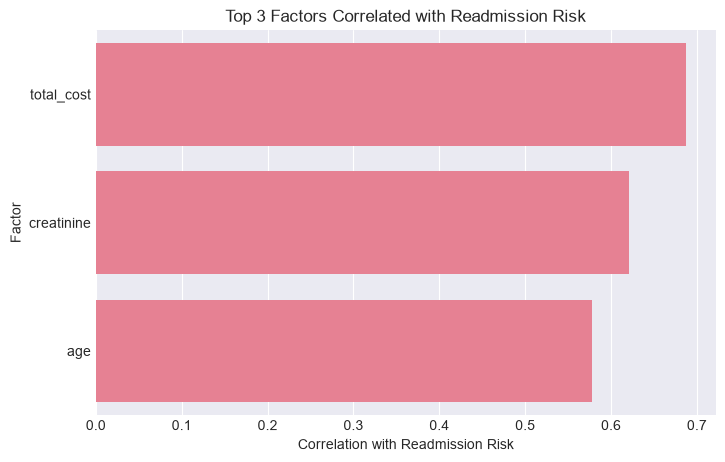

In [58]:
plt.figure(figsize=(8, 5))

top_3_values = risk_corr[top_3.index]

sns.barplot(
    x=top_3_values.values,
    y=top_3_values.index
)

plt.title("Top 3 Factors Correlated with Readmission Risk")
plt.xlabel("Correlation with Readmission Risk")
plt.ylabel("Factor")
plt.show()

**Your Answer:**

1. Total Cost has the strongest positive correlation with readmission risk (0.69).
2. Creatinine has the second-strongest positive correlation (0.62).
3. Age has the third-strongest positive correlation (0.58).

## Question 2: Which medical conditions have the highest treatment costs?

In [59]:
condition_cost = df.groupby("primary_diagnosis")["total_cost"].mean().sort_values(ascending=False)

print(condition_cost)


primary_diagnosis
Neurological        15846.702303
Cardiovascular      12519.327088
Respiratory         10391.572165
Gastrointestinal     9323.440963
Orthopedic           8006.276714
Name: total_cost, dtype: float64


**Your Answer:**
- Neurological conditions have the highest average treatment cost
- Cardiovascular conditions have the second highest average treatment cost
- Respiratory conditions have the third highest avearge treatment cost


## Question 3: Which admission types lead to the longest hospital stays?

In [60]:
admission_stay = df.groupby("admission_type")["length_of_stay"].mean().sort_values(ascending=False)

print(admission_stay)



admission_type
Trauma       9.305080
Emergency    6.622548
Urgent       5.264984
Elective     3.815181
Name: length_of_stay, dtype: float64


**Your Answer:**

- Trauma admissions have the longest average hospital stay, about 9.31 days.
- Emergency admissions have the second-longest average stay, about 6.62 days.
- Urgent admissions average about 5.26 days, while Elective admissions have the shortest average stay at about 3.82 days

## Question 4: Is there a relationship between age, gender, and readmission risk?

In [61]:
age_gender_risk = df.groupby(
    ["gender", "readmission_risk"]
)["age"].mean()

print(age_gender_risk)



gender  readmission_risk
F       0                   52.750722
        1                   66.219178
        2                   76.975690
M       0                   52.755279
        1                   66.384557
        2                   77.032872
Name: age, dtype: float64


**Your Answer:**
Older patients have higher readmission risk.
The pattern is almost the same for males and females.
Age has a stronger relationship with readmission risk than gender.


## Question 5: What patient profile represents the highest readmission risk?

In [62]:
high_risk = df[df["readmission_risk"] == 2]

print(high_risk[["age", "gender", "length_of_stay", "total_cost"]].mean(numeric_only=True))
print(high_risk["gender"].value_counts())



age                  77.003183
length_of_stay        9.600809
total_cost        16160.755168
dtype: float64
gender
F    55450
M    51351
Name: count, dtype: int64


**Your Answer:**
Older patients represent the higher readmission-risk group.
They generally have longer hospital stays.
They also tend to have higher treatment costs.



---
# 📈 Section 8: Dashboard & Executive Summary

Create a multi-panel dashboard and write your executive summary.

## Task 8.1: Create Dashboard

**YOUR TASK:** Create a multi-panel figure with at least 4 subplots and save it to `../outputs/figures/dashboard.png`.

2026-09-20 23:50:41,858 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-09-20 23:50:42,814 - INFO     - Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


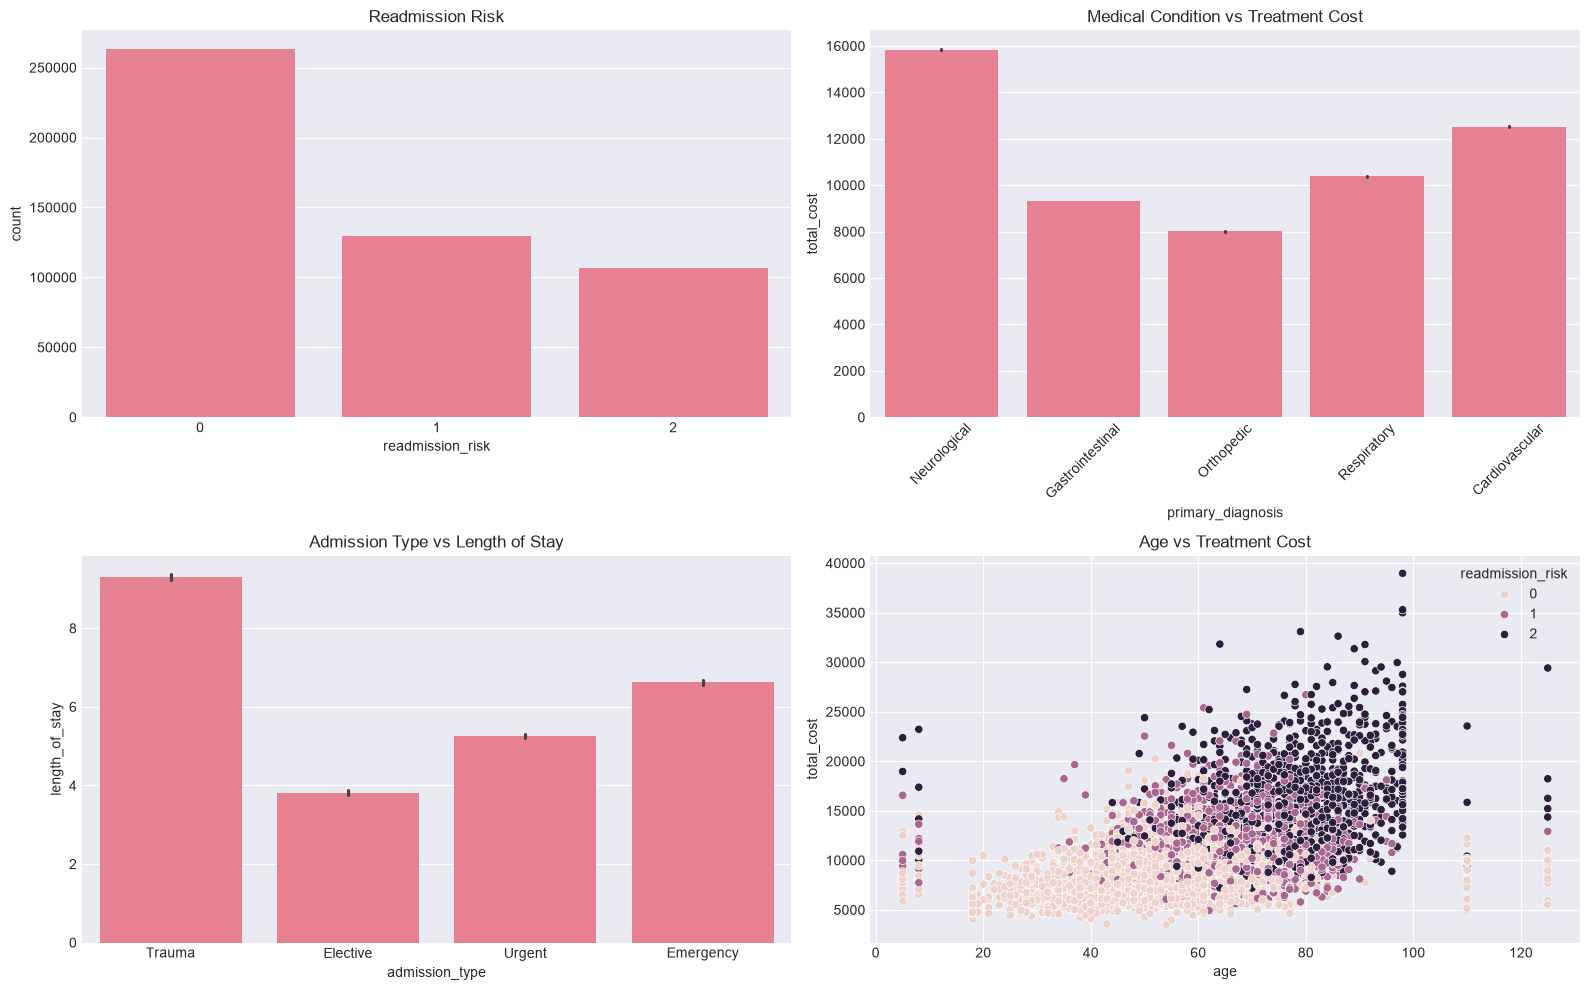

In [63]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Readmission Risk
sns.countplot(data=df, x="readmission_risk", ax=axes[0, 0])
axes[0, 0].set_title("Readmission Risk")

# 2. Medical Condition vs Treatment Cost
sns.barplot(
    data=df,
    x="primary_diagnosis",
    y="total_cost",
    ax=axes[0, 1]
)
axes[0, 1].set_title("Medical Condition vs Treatment Cost")
axes[0, 1].tick_params(axis="x", rotation=45)

# 3. Admission Type vs Length of Stay
sns.barplot(
    data=df,
    x="admission_type",
    y="length_of_stay",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Admission Type vs Length of Stay")

# 4. Age vs Treatment Cost
sns.scatterplot(
    data=df.sample(5000),
    x="age",
    y="total_cost",
    hue="readmission_risk",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Age vs Treatment Cost")

plt.tight_layout()

plt.savefig("../outputs/figures/dashboard.png", dpi=150, bbox_inches="tight")

plt.show()




## Task 8.2: Export Cleaned Dataset

**YOUR TASK:** Save the cleaned + engineered dataset to `../outputs/cleaned_data.csv`.

In [64]:
df.to_csv("../outputs/cleaned_data.csv", index=False)
print("Cleaned dataset saved successfully!")



Cleaned dataset saved successfully!


## Task 8.3: Executive Summary

### Overview

This healthcare dataset contains 500,000 patient records. The analysis was performed to understand readmission risk, treatment costs, hospital stays, and patient characteristics. The findings can help hospitals improve patient care, manage resources, and understand cost patterns.

### Key Findings

1. Readmission risk is strongly related to treatment cost. Total cost has a positive correlation of about 0.69 with readmission risk.

2. Age is also related to readmission risk. Higher-risk patients are generally older than lower-risk patients.

3. Neurological conditions have the highest average treatment cost, followed by Cardiovascular and Respiratory conditions.

4. Trauma admissions have the longest average hospital stay at about 9.31 days, followed by Emergency admissions at about 6.62 days.

5. Higher readmission-risk patients generally have higher treatment costs and longer hospital stays.

### Recommendations

1. Give closer follow-up care to patients with higher readmission risk.

2. Monitor older patients more carefully after discharge.

3. Review treatment and resource requirements for high-cost medical conditions.

4. Give special attention to patients with long hospital stays.

5. Use readmission risk information to support hospital resource planning.

6. Monitor treatment costs regularly to identify areas where costs can be reduced.

### Conclusion

The analysis shows that age, readmission risk, treatment cost, medical condition, and length of stay are important factors in the healthcare dataset. These findings can help hospitals improve patient monitoring, manage resources, and control treatment costs.

---
# ✅ Section 9: Final Checklist

Before submitting, verify:
- [ ] Notebook runs top-to-bottom without errors
- [ ] All `# YOUR CODE HERE` sections completed
- [ ] Every chart has a title and axis labels
- [ ] Observations written in markdown cells
- [ ] Dataset exported to `outputs/cleaned_data.csv`
- [ ] Dashboard saved to `outputs/figures/dashboard.png`
- [ ] Executive summary completed
- [ ] Presentation prepared (optional)
- [ ] Committed and pushed to GitHub

---

**Good luck! 📊**